# Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,accuracy_score
from statsmodels.tsa.stattools import grangercausalitytests
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder,StandardScaler

In [2]:
#Εισαγωγή δεδομένων
df=pd.read_csv("airline_passenger_satisfaction.csv")
# Αρχική Εικόνα
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 24 columns):
 #   Column                                  Non-Null Count   Dtype  
---  ------                                  --------------   -----  
 0   ID                                      129880 non-null  int64  
 1   Gender                                  129880 non-null  object 
 2   Age                                     129880 non-null  int64  
 3   Customer Type                           129880 non-null  object 
 4   Type of Travel                          129880 non-null  object 
 5   Class                                   129880 non-null  object 
 6   Flight Distance                         129880 non-null  int64  
 7   Departure Delay                         129880 non-null  int64  
 8   Arrival Delay                           129487 non-null  float64
 9   Departure and Arrival Time Convenience  129880 non-null  int64  
 10  Ease of Online Booking                  1298

In [3]:
#Συμπληρώνουμε τις ελλειπούσες τιμές με το μέσο όρο της αντίστοιχης μεταβλητής.
df['Arrival Delay']=df['Arrival Delay'].fillna(df['Arrival Delay'].mean())
df.head()# Βλέπουμε τις 5 πρώτες εγγραφές.

,ID,Gender,Age,Customer Type,Type of Travel,Class,Flight Distance,Departure Delay,Arrival Delay,Departure and Arrival Time Convenience,...,On-board Service,Seat Comfort,Leg Room Service,Cleanliness,Food and Drink,In-flight Service,In-flight Wifi Service,In-flight Entertainment,Baggage Handling,Satisfaction
0,1,Male,48,First-time,Business,Business,821,2,5.0,3,...,3,5,2,5,5,5,3,5,5,Neutral or Dissatisfied
1,2,Female,35,Returning,Business,Business,821,26,39.0,2,...,5,4,5,5,3,5,2,5,5,Satisfied
2,3,Male,41,Returning,Business,Business,853,0,0.0,4,...,3,5,3,5,5,3,4,3,3,Satisfied
3,4,Male,50,Returning,Business,Business,1905,0,0.0,2,...,5,5,5,4,4,5,2,5,5,Satisfied
4,5,Female,49,Returning,Business,Business,3470,0,1.0,3,...,3,4,4,5,4,3,3,3,3,Satisfied


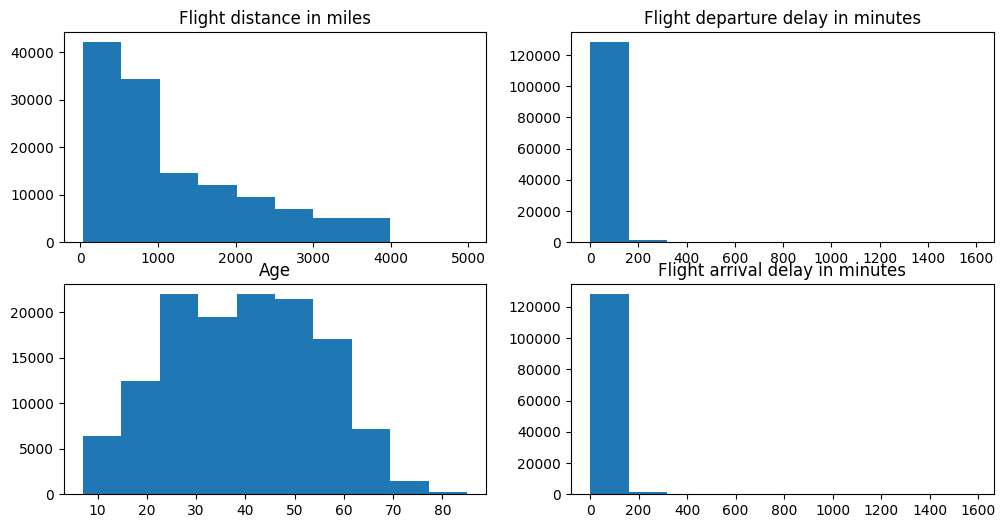

In [4]:
#Δημιουργία Ιστογραμμάτων
fig, ax = plt.subplots(2, 2,figsize=(12,6))
ax[1,0].hist(df['Age'])
ax[1,0].set_title("Age")
ax[0,0].hist(df['Flight Distance'])
ax[0,0].set_title("Flight distance in miles")
ax[0,1].hist(df['Departure Delay'])
ax[0,1].set_title("Flight departure delay in minutes")
ax[1,1].hist(df['Arrival Delay'])
ax[1,1].set_title("Flight arrival delay in minutes")
plt.show()


In [5]:
# Δημιουργία ομάδων μεταβλητών.
ordered_categorigal_variables_1=[
'Departure and Arrival Time Convenience',
'Ease of Online Booking',
'Check-in Service',
'Online Boarding',
'Gate Location',
'On-board Service',
'Seat Comfort',
'Leg Room Service',
'Cleanliness',
'Food and Drink',
'In-flight Service',
'In-flight Wifi Service',
'In-flight Entertainment',
'Baggage Handling']
ordered_categorigal_variables_2=['Class','Satisfaction']
unordered_categorical_variables=['Customer Type','Type of Travel','Gender']
categorigal_variables=[]
categorigal_variables.extend(ordered_categorigal_variables_1)
categorigal_variables.extend(ordered_categorigal_variables_2)
categorigal_variables.extend(unordered_categorical_variables)

In [6]:
#Ορισμός-Κωδικοποίηση των κατηγορικών μεταβλητών ως κατηγορικές και διατάξιμες.
for i in ordered_categorigal_variables_1:
  df[i]=pd.Categorical(df[i],categories=[0,1,2,3,4,5],ordered=True)

df['Class']=df['Class'].map({'Economy':1 ,'Economy Plus':2 ,'Business':3})
df['Class']=pd.Categorical(df['Class'],categories=[1,2,3],ordered=True)


df['Satisfaction']=df['Satisfaction'].map({'Neutral or Dissatisfied':0 ,'Satisfied':1})
df['Satisfaction']=pd.Categorical(df['Satisfaction'],categories=[0, 1],ordered=True)

In [7]:
#Κωδικοποίηση των μη διατάξιμων κατηγορικών μεταβλητών με ONE HOT ENCODER
CT= df[['Customer Type']].select_dtypes(include=['object']).columns
encoder=OneHotEncoder(sparse_output=False)
encoded_CT=encoder.fit_transform(df[['Customer Type']])
encoded_df_1=pd.DataFrame(encoded_CT,columns=encoder.get_feature_names_out(CT))


TT= df[['Type of Travel']].select_dtypes(include=['object']).columns
encoded_TT=encoder.fit_transform(df[['Type of Travel']])
encoded_df_2=pd.DataFrame(encoded_TT,columns=encoder.get_feature_names_out(TT))

G= df[['Gender']].select_dtypes(include=['object']).columns
encoded_G=encoder.fit_transform(df[['Gender']])
encoded_df_3=pd.DataFrame(encoded_G,columns=encoder.get_feature_names_out(G))

df = pd.concat([df.drop(columns=['Customer Type','Type of Travel','Gender','ID']), encoded_df_1,encoded_df_2,encoded_df_3],axis=1)


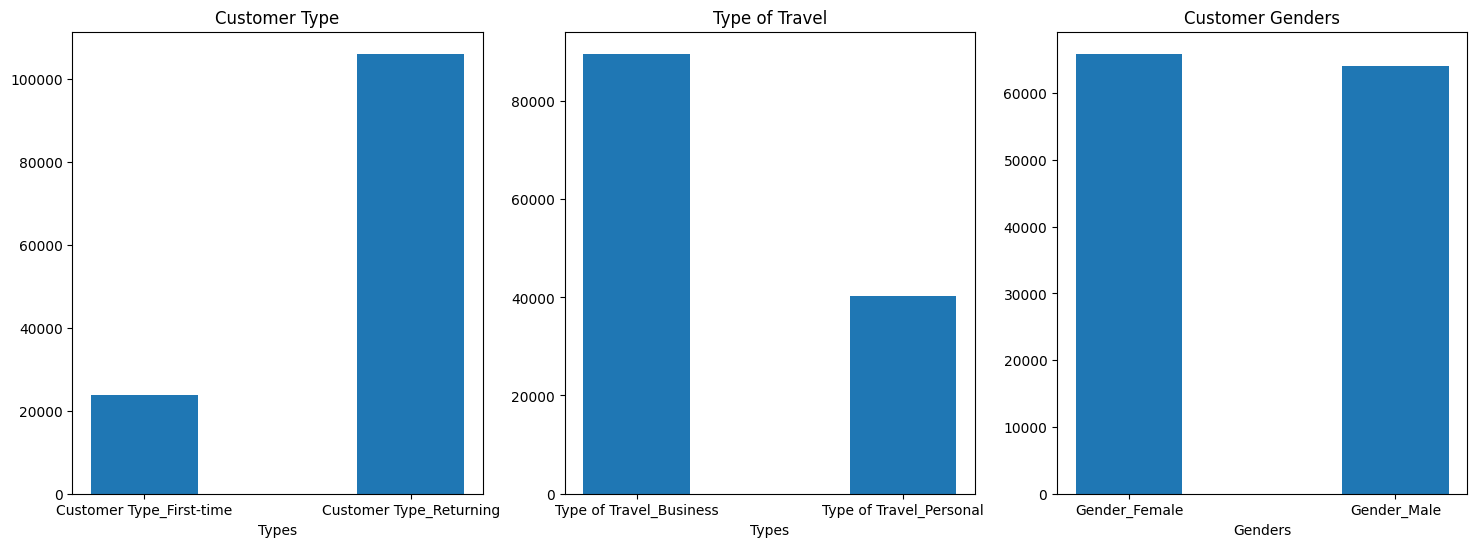

In [8]:
#Δημιουργία ραβδογράμματος για τις μη διατάξιμες κατηγορικές μεταβλητές.
fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].bar(['Customer Type_First-time','Customer Type_Returning'],[encoded_df_1['Customer Type_First-time'].sum(),encoded_df_1['Customer Type_Returning'].sum()],width=0.4)
ax[0].set_xlabel("Types")
ax[0].set_title("Customer Type")

ax[1].bar(['Type of Travel_Business','Type of Travel_Personal'],[encoded_df_2['Type of Travel_Business'].sum(),encoded_df_2['Type of Travel_Personal'].sum()],width=0.4)
ax[1].set_xlabel("Types")
ax[1].set_title("Type of Travel")



ax[2].bar(['Gender_Female','Gender_Male'],[encoded_df_3['Gender_Female'].sum(),encoded_df_3['Gender_Male'].sum()],width=0.4)
ax[2].set_xlabel("Genders")
ax[2].set_title("Customer Genders")
plt.show()


Είναι προφανές ότι οι περισσότεροι πελάτες είναι "σταθεροί" πελάτες της εταιρείας,ενώ το μεγαλύτερο πλήθος των ταξιδιών αφορά επαγγελματικά ταξίδια.Επιπλέον, οι γυναίκες φαίνεται να είναι οι καλύτερες πελάτισσες της εταιρείας, χωρίς ωστόσο να υπάρχει μεγάλη διαφοροποίηση από του άντρες.

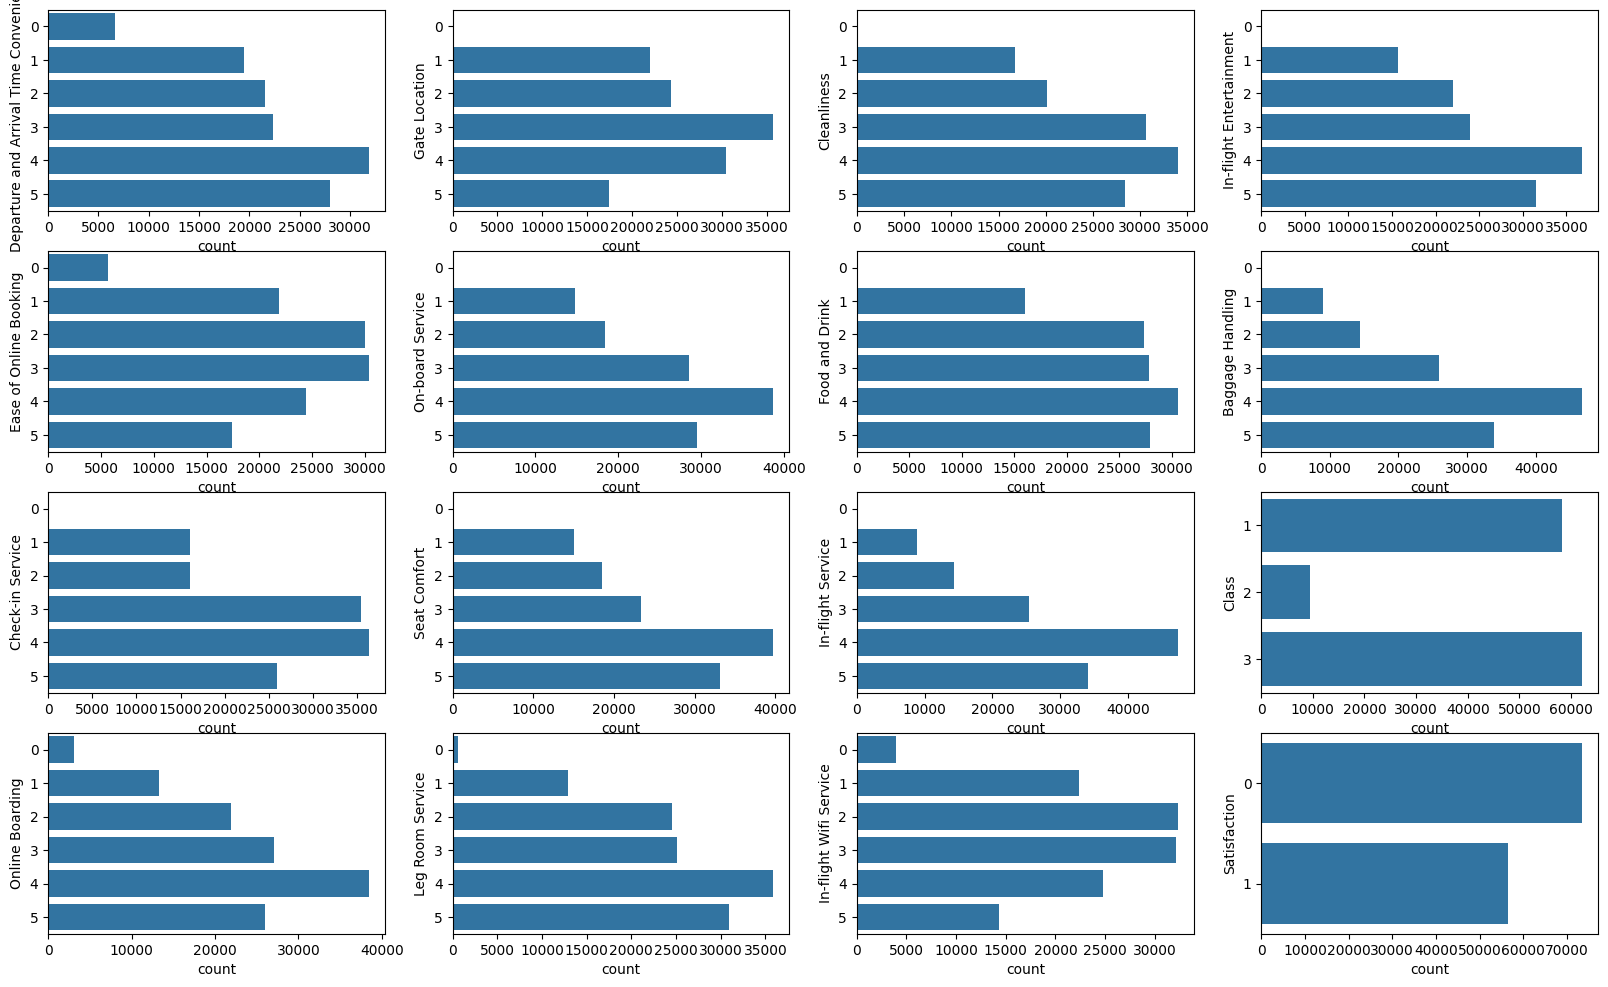

In [9]:
#Ραβδογράμματα για τις διαταξιμες κατηγορικές μεταβλητές.
fig, ax = plt.subplots(4, 4,figsize=(20,12))
for j,i in enumerate(categorigal_variables[0:4]):
  sns.countplot(df[i],ax=ax[j,0])
for j,i in enumerate(categorigal_variables[4:8]):
  sns.countplot(df[i],ax=ax[j,1])
for j,i in enumerate(categorigal_variables[8:12]):
  sns.countplot(df[i],ax=ax[j,2])
for j,i in enumerate(categorigal_variables[12:16]):
  sns.countplot(df[i],ax=ax[j,3])
plt.show()

Το επίπεδο ικανοποίηση για τις μεταβλητές "Departure and Arrival Time","Convenience","Check-in Service","Online Boarding","On-board Service","Seat Comfort","Leg Room Service","Cleanliness","Food and Drink","In-flight Service","In-flight Entertainment","Baggage Handling" ανέρχεται στο **4/5**.

Για τις μεταβλητές "Ease of Online Booking" και "Gate Location" στο **3/5**. Ενώ για την "In-flight Wifi Service" στο **2/5**.

Επιπλέον, οι περισσότεροι πελάτες επιλέγουν την **επαγγελματική κλάση** για τα ταξίδια τους η οποία υπερισχύει των άλλων δύο.

Με τον παρακάτω κώδικα κανονικοποιούμε μόνο τις αιθμητικές τιμές. Η κανονιποιποίηση των κατηγορικών μεταβλητών δεν έχει νόημα, καθώς η διάταξή τους μας δίνει την πληροφορία που χρειάζεται ο αλγόριθμος για να προβλέψει.

In [10]:
#Κανονικοποίηση για τις αριθμητικές μεταβλητές.
scale=StandardScaler()
df[['Flight Distance', 'Departure Delay','Arrival Delay']]=scale.fit_transform(df[['Flight Distance', 'Departure Delay','Arrival Delay']])

In [11]:
#Δημιουργία των συνόλων input, targets σύμφωνα με το ζητούμενο της άσκησης.
input_df = df.drop(columns=['Satisfaction'])
targets_df = df['Satisfaction']

x = input_df.to_numpy()
y = targets_df.to_numpy()
x.shape, y.shape

((129880, 25), (129880,))

In [12]:
#Χωρίζουμε το δείγμα σε σύνολο εκπαίδευσης και επικύρωσης.
seed = 0
test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=test_size, random_state=seed)
x_train.shape, y_train.shape, x_test.shape, y_test.shape

((90916, 25), (90916,), (38964, 25), (38964,))

In [13]:
accuracy_percentages=[]#Κενή λίστα για να τη συμπληρώσουμε
k=[3,5,15,51,151,int(round(np.sqrt(len(x_train)),0))]# Οι τιμές του κ για τις οποίες θα τρέξουμε τον αλγόριθμο.
for k in k :
  knn=KNeighborsClassifier(n_neighbors=k,weights='uniform', metric='euclidean') #ορισμός μοντέλου
  knn.fit(x_train,y_train)# εκπαίδευση του μοντέλου
  y_pred = knn.predict(x_test) # προβλέψεις
  accuracy = accuracy_score(y_test, y_pred)
  accuracy_percentage = round(accuracy*100, 2)
  L1=[accuracy_percentage]
  accuracy_percentages.extend(L1) # συμπλήρωση λίστας
  print(f'The accuracy of the model is: {accuracy_percentage}')


The accuracy of the model is: 91.33
The accuracy of the model is: 91.66
The accuracy of the model is: 91.59
The accuracy of the model is: 90.63
The accuracy of the model is: 89.24
The accuracy of the model is: 88.16


In [14]:
max_k=int(round(np.sqrt(len(x_train)),0))
print(f'Maximum value of k is : {max_k}')

Maximum value of k is : 302


Στο παρακάτω διάγραμμα φαίνεται η ακρίβεια για τις διάφορες τιμές του k με μέγιστη τιμή την $k = \sqrt{N}=302$.



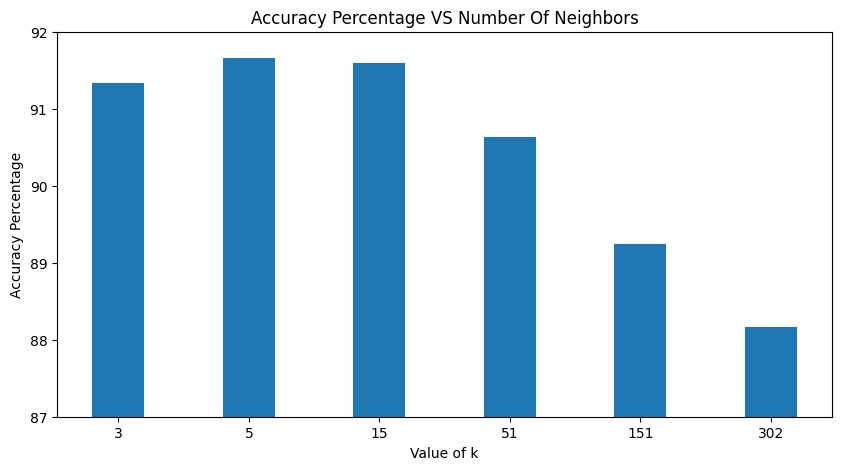

In [15]:
#Δημιουργία ραβδογράμματος
k_labels=["3","5","15","51","151","302"]
plt.figure(figsize=(10, 5))
plt.bar(k_labels,accuracy_percentages,width=0.4)
plt.ylim(87,92)
plt.xlabel("Value of k")
plt.ylabel("Accuracy Percentage")
plt.title("Accuracy Percentage VS Number Of Neighbors")
plt.show()

Όπως φαίνεται από το παραπάνω διάγραμμα, η καλύτερη επιλογή για το k είναι το 5. Παρατηρούμε ότι, όσο αυξάνεται η τιμή του k  η ακρίβεια του μοντέλου ξεκινάει να μειώνεται.